In [1]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt

In [2]:
def photons_to_qubits(photons):
    '''
    Converts tuple of photon numbers (n,m) into qubit bitstring.
    Works only for N=4.
    '''
    qubits = ''
    for mode in photons:
        binary = format(mode, '02b')  # Convert to 2-bit binary
        qubits += binary
    vector_id = int(qubits, 2)  # Convert the full binary string to an integer
    vector = np.zeros(16)  # Initialize a vector of size 16 (2^4)
    vector[vector_id] = 1  # Set the corresponding index to 1
    return vector

In [3]:
def qubits_to_photons(index): # This function takes the vecotr index directly as input
    binary = format(index, '04b')  # Convert the index to a 4-bit binary string
    photons = []
    for i in range(0, len(binary), 2):
        mode = int(binary[i:i+2], 2)  # Convert each 2-bit segment back to an integer
        photons.append(mode)
    return photons

In [5]:
# inputs and outputs if ideal BS for training, comment out which you don't want to include in cost function
inputs = [
    photons_to_qubits([0,0]),
    photons_to_qubits([0,1]),
    photons_to_qubits([1,0]),
    photons_to_qubits([0,2]),
    photons_to_qubits([1,1]),
    photons_to_qubits([2,0]),

    # photons_to_qubits([0,3]),
    # photons_to_qubits([1,2]),
    # photons_to_qubits([2,1]),
    # photons_to_qubits([3,0]),

    # photons_to_qubits([1,3]),
    # photons_to_qubits([2,2]),
    # photons_to_qubits([3,1]),

    # photons_to_qubits([2,3]),
    # photons_to_qubits([3,2]),
    # photons_to_qubits([3,3]),

]
outputs = [
    photons_to_qubits([0,0]),
    1/np.sqrt(2)*photons_to_qubits([0,1]) + 1/np.sqrt(2)*photons_to_qubits([1,0]),
    -1/np.sqrt(2)*photons_to_qubits([0,1]) + 1/np.sqrt(2)*photons_to_qubits([1,0]),
    1/2*photons_to_qubits([0,2]) + 1/np.sqrt(2)*photons_to_qubits([1,1])+ 1/2*photons_to_qubits([2,0]),
    -1/np.sqrt(2)*photons_to_qubits([0,2]) + 1/np.sqrt(2)*photons_to_qubits([2,0]),
    1/2*photons_to_qubits([0,2]) - 1/np.sqrt(2)*photons_to_qubits([1,1])+ 1/2*photons_to_qubits([2,0]),

    # np.sqrt(2)/4*photons_to_qubits([0,3]) + np.sqrt(6)/4*photons_to_qubits([1,2]) + np.sqrt(6)/4*photons_to_qubits([2,1]) + np.sqrt(2)/4*photons_to_qubits([3,0]),
    # -np.sqrt(2)/4*photons_to_qubits([0,3]) - np.sqrt(6)/4*photons_to_qubits([1,2]) + np.sqrt(6)/4*photons_to_qubits([2,1]) + np.sqrt(2)/4*photons_to_qubits([3,0]),
    # np.sqrt(2)/4*photons_to_qubits([0,3]) - np.sqrt(6)/4*photons_to_qubits([1,2]) - np.sqrt(6)/4*photons_to_qubits([2,1]) + np.sqrt(2)/4*photons_to_qubits([3,0]),
    # -np.sqrt(2)/4*photons_to_qubits([0,3]) + np.sqrt(6)/4*photons_to_qubits([1,2]) - np.sqrt(6)/4*photons_to_qubits([2,1]) + np.sqrt(2)/4*photons_to_qubits([3,0]),

    # (1+np.cos(np.pi*np.sqrt(3)/2))/2*photons_to_qubits([1,3]) + np.sin(np.pi*np.sqrt(3)/2)/np.sqrt(2)*photons_to_qubits([2,2]) + (1-np.cos(np.pi*np.sqrt(3)/2))/2*photons_to_qubits([3,1]),
    # -np.sin(np.pi*np.sqrt(3)/2)/np.sqrt(2)*photons_to_qubits([1,3]) + np.cos(np.pi*np.sqrt(3)/2)*photons_to_qubits([2,2]) + np.sin(np.pi*np.sqrt(3)/2)/np.sqrt(2)*photons_to_qubits([3,1]),
    # (1-np.cos(np.pi*np.sqrt(3)/2))/2*photons_to_qubits([1,3]) - np.sin(np.pi*np.sqrt(3)/2)/np.sqrt(2)*photons_to_qubits([2,2]) + (1+np.cos(np.pi*np.sqrt(3)/2))/2*photons_to_qubits([3,1]),

    # -1/np.sqrt(2)*photons_to_qubits([2,3]) + 1/np.sqrt(2)*photons_to_qubits([3,2]),
    # -1/np.sqrt(2)*photons_to_qubits([2,3]) - 1/np.sqrt(2)*photons_to_qubits([3,2]),
    # photons_to_qubits([3,3]),

]

In [6]:
dev = qml.device("default.qubit", wires=4)

@qml.qnode(dev)
def ansatz_circ(initial_layer_weights, weights, init_vector):
    qml.StatePrep(init_vector, wires=range(4))
    qml.SimplifiedTwoDesign(initial_layer_weights, weights, wires=range(4))
    return qml.state()

In [7]:
def cost(initial_layer_weights, weights):
    cost_value = 0
    for input_vec, output_vec in zip(inputs, outputs):    
        cost_value += np.dot(
            ansatz_circ(initial_layer_weights, weights, input_vec),
            output_vec.conj()
        )
    return np.real_if_close(1-cost_value/len(inputs))

In [8]:
num_layers_for_ansatz = 10
shape_init, shape_weights = qml.SimplifiedTwoDesign.shape(num_layers_for_ansatz,4)
initial_layer_weights = np.random.random(shape_init)
weights = np.random.random(shape_weights)

params = [initial_layer_weights, weights]

In [10]:
opt = qml.AdamOptimizer(stepsize=0.1)

max_steps = 100

for step in range(max_steps):
    params, cost_val = opt.step_and_cost(cost, *params)
    if step % 10 == 0:
        print(f"Step {step}, Cost: {cost_val}")

print(f"Final cost: {cost(*params)}")

Step 0, Cost: 0.02177643081027769
Step 10, Cost: 0.025545823418753777
Step 20, Cost: 0.02037167737732104
Step 30, Cost: 0.016733257140024715
Step 40, Cost: 0.012594461948860491
Step 50, Cost: 0.00890897085827147
Step 60, Cost: 0.006342446854958772
Step 70, Cost: 0.004093566448409192
Step 80, Cost: 0.0034718595177846145
Step 90, Cost: 0.003043265520628058
Final cost: 0.0027200254087550446


Text(0.5, 1.0, 'Output probability distribution for input [2, 0]')

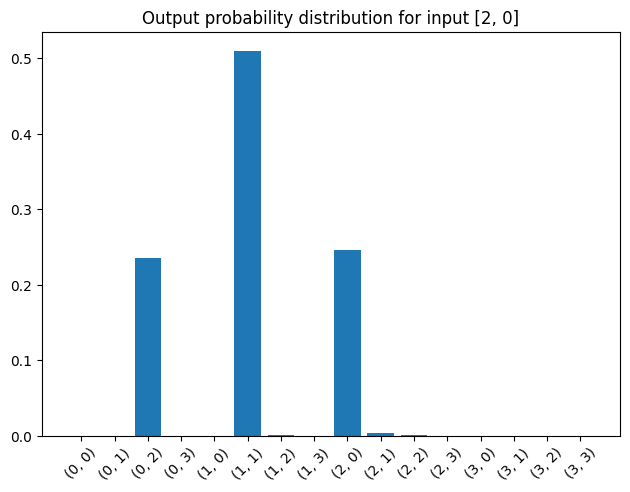

In [13]:
input_photon_state = [2,0]

output_state_photons_probs = {}
for id, element in enumerate(ansatz_circ(*params, photons_to_qubits(input_photon_state))):
    output_state_photons_probs[tuple(qubits_to_photons(id))] = np.abs(element)**2
plt.bar(range(len(output_state_photons_probs)), list(output_state_photons_probs.values()), tick_label=[str(key) for key in output_state_photons_probs.keys()])
plt.xticks(rotation=45)
plt.tight_layout()
plt.title(f'Output probability distribution for input {input_photon_state}')